In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

#import os
#for dirname, _, filenames in os.walk('/kaggle/input'):
 #   for filename in filenames:
  #      print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Introducción 


Para nadie es un secreto que los grandes avances de la humanidad, están  basados en como se precibe la naturaleza. Las alas de los aviones, las agujas, los submarinos, etc. Son solo algunos ejemplos de cómo la observación humana a logrado inspirarse en el fenómeno de la vida para hacer más provechosa su existencia.
Gracias al desarrollo computacional de las últimas décadas, se ha logrado llegar a el pináculo  de la inspiración  humana, la **red neuronal**. El universo complejo alojado en nuestras mentes, siempre ha sido una de las mayores interrogantes del mundo, con el pasar de los años, se ha logrado develar poco a poco ésta incógnita, permitiendonos avanzar en lo que hoy conocemos como **Inteligencia Artificial (IA)**.
En la actualidad, la inteligencia artificial ha logrado permear todos los campos del desarrollo humano, por lo que la moda no está excepta de ésta.
Nuestro trabajo pretende desarrollar un sistema de clasificación de ropa,es decir, buscamos que nuestra red neuronal tenga la capacidad de diferenciar entre un pantalón, un camisa o unos zapatos. Para esto, vamos a sacar partido de las redes neuronales convolucionales (CNN), éstas, son un tipo de redes neuronales que a diferencia de las redes neuronales recurrentes (RNN),son redes neuronales feedforward con pesos compartidos e interacciones dispersas, es decir, la mayoría de los pesos son iguales a cero. Dado su menor número de parámetros, las redes de convolución son más eficientes de entrenar que cualquier red de capa completamente conectada de tamaño similar, con solo consecuencias negativas menores en su rendimiento. El excelente rendimiento de las CNN en el procesamiento de imágenes se debe a su adaptabilidad a una topología similar a una cuadrícula 2D. CNN es una pieza de IA de inspiración biológica, cuyo diseño se basa en principios neurocientíficos y se aplica con éxito al reconocimiento de patrones. Al igual que casi cualquier otra red neuronal feedforward, las CNN se entrenan con una versión del algoritmo de retropropagación y utilizan ReLU como función de activación.

# Marco Teórico 

Ya mencionamos que vamos a utilizar una red neuronal convolucional(CNN), pero para ser más precisos, vamos a utilizar una red neuronal llamada VGG.
VGG(Grupo de Geometría Visual) es una red neuronal convolucional propuesta por K. Simonyan y A. Zisserman, de la Universidad de Oxford, y adquirió notoriedad al ganar el Desafío de Reconocimiento Visual a Gran Escala de ImageNet (ILSVRC) en 2014. El modelo alcanzó una precisión del 92,7% en Imagenet, que es una de las puntuaciones más altas logradas. Supone una mejora respecto a los modelos anteriores al **proponer núcleos de convolución más pequeños (3×3**) en las capas de convolución de lo que se había hecho anteriormente. El modelo se entrenó durante semanas utilizando tarjetas gráficas de última generación.

La entrada de VGG se establece en una imagen RGB de tamaño 224x244. El valor RGB promedio se calcula para todas las imágenes de la imagen del conjunto de entrenamiento y, a continuación, la imagen se ingresa como entrada a la red de convolución VGG. Se utiliza un filtro de 3x3 o 1x1 y se fija el paso de convolución. Hay 3 capas VGG totalmente conectadas, que pueden variar de VGG11 a VGG19 según el número total de capas convolucionales + capas totalmente conectadas. En nuestro caso vamos a utilizar una red neuronal VGG16.

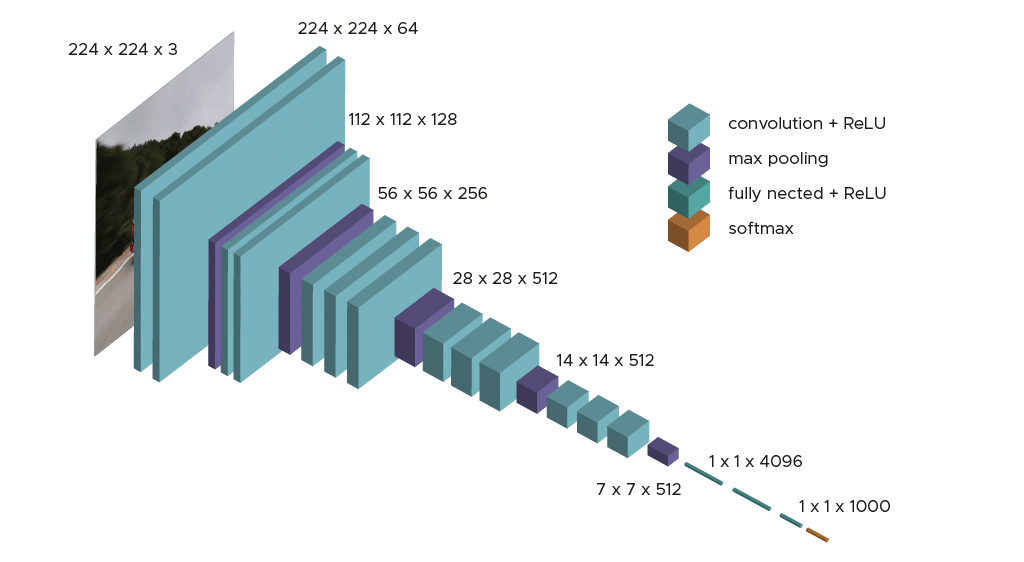

![VGGA2.webp](https://miro.medium.com/v2/resize:fit:1400/format:webp/0*E8ttL5YuOVu58ky_.png)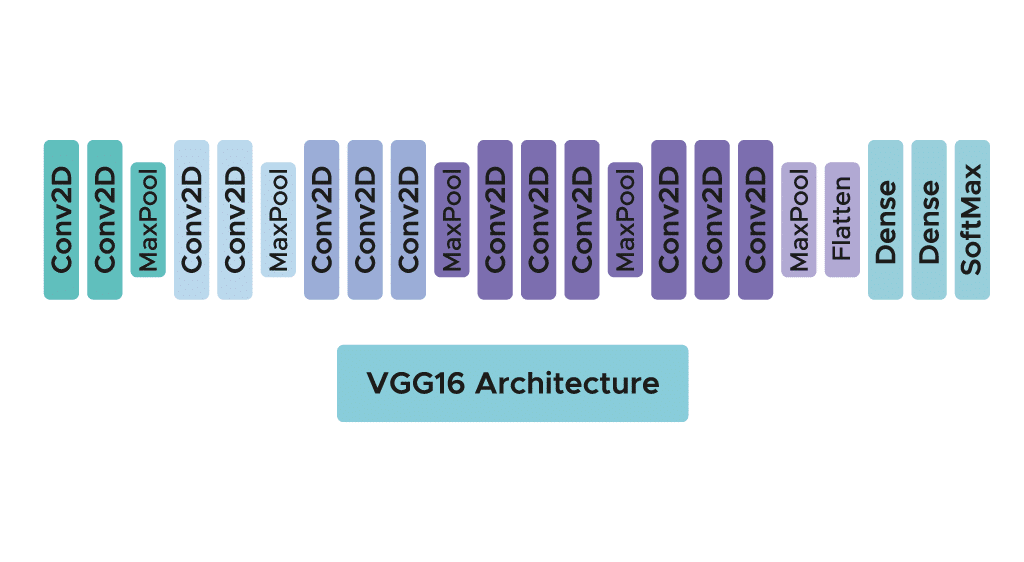

La estructura general incluye 5 conjuntos de capas convolucionales, seguidas de un MaxPool. La diferencia es que cada vez se incluyen más capas convolucionales en cascada en los cinco conjuntos de capas convolucionales. En una red VGG, cada capa de convolución contiene de 2 a 4 operaciones de convolución. El tamaño del kernel de convolución es 3 * 3, el tamaño del paso de convolución es 1, el kernel de agrupación es 2 * 2 y el tamaño del paso es 2. La mejora más obvia de la red VGG es reducir el tamaño del kernel de convolución y aumentar el número de capas de convolución. El uso de múltiples capas de convolución con kernels de convolución más pequeños en lugar de una capa de convolución más grande con kernels de convolución puede reducir los parámetros, por un lado, y el autor cree que es equivalente a un mapeo más no lineal, lo que aumenta la capacidad de expresión de ajuste.
Dos circunvoluciones consecutivas de 3 * 3 equivalen a un campo receptivo de 5 * 5, y tres equivalen a 7 * 7. Las ventajas de usar tres convoluciones de 3 * 3 en lugar de una convolución de 7 * 7 son dobles: una, que incluye tres capas de ReLu en lugar de una, hace que la función de decisión sea más discriminativa; y dos, la reducción de parámetros. Por ejemplo, la entrada y la salida son todos canales C. 3 capas convolucionales que usan 3 * 3 requieren 3 (3 * 3 * C * C) = 27 * C * C, y 1 capa convolucional que usa 7 * 7 * C * C = 49C * C. Esto se puede ver como la aplicación de una especie de regularización a la convolución de 7 * 7, de modo que se descompone en tres convoluciones de 3 * 3.
La capa de convolución 1 * 1 es principalmente para aumentar la no linealidad de la función de decisión sin afectar el campo receptivo de la capa de convolución. Aunque la operación de convolución 1 * 1 es lineal, ReLu agrega no linealidad.


![VGG163.webp](https://miro.medium.com/v2/resize:fit:1400/format:webp/0*F2EriOvWmcdLDmPH.jpg)

**Función ReLU** (rectified linear activation function): Definida cómo $y=f(x)=max(0,x)$ donde '$x$' es la entrada de la neurona. $f(x)$ es cero cuando $x$ es menor que cero y luego se dispara hacia arriba en forma lineal donde $f(x)$ es igual a $x$ cuando $x$ es superior o igual a cero. Su rango o codominio es $[0, +∞)$ y tanto la función como su derivada son monótonas.

Su poderío radica en que todos los valores negativos se vuelven cero, y eso significa que cualquier entrada negativa dada a la función de activación de ReLU convierte el valor en cero inmediatamente. Esto puede ayudar mucho en la simplificación computacional ya que todos los valores iguales a $0$ son inmediatamente descartados (dichas neuronas son irrelevantes). A su vez esto puede disminuir la capacidad del modelo para ajustarse o entrenarse a partir de los datos correctamente.

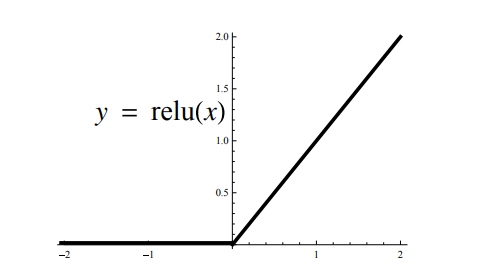

**Función SoftMax:** La función softmax, o función exponencial normalizada, es una generalización de la Función logística. Se emplea para "comprimir" un vector $K-$dimensional, z{$\displaystyle \mathbf {z}$ }, de valores reales arbitrarios en un vector $K-$dimensional,{$\displaystyle \sigma (\mathbf {z} )$}, de valores reales en el rango [0, 1]. La función está dada por:

$\sigma(z)_{j}$= $\frac{e^{z_j}}{\sum_{k=1}^{K}e^{z_k}}$    para $j = 1, …, K$.

La función softmax es una de las funciones estrella en la última capa de la red. Ya que permite realizar una clasificación categórica multiclase. Esto se debe a que por su forma sigmoidea clasifica entre valores de $0$ y $1$ (probabilidad) pero a diferencia de la sigmoide o de la tanh es muy diferenciable y no empuja la salida hacia los extremos $0$ y $1$ (o $-1$ y $1$ para el caso de tanh).

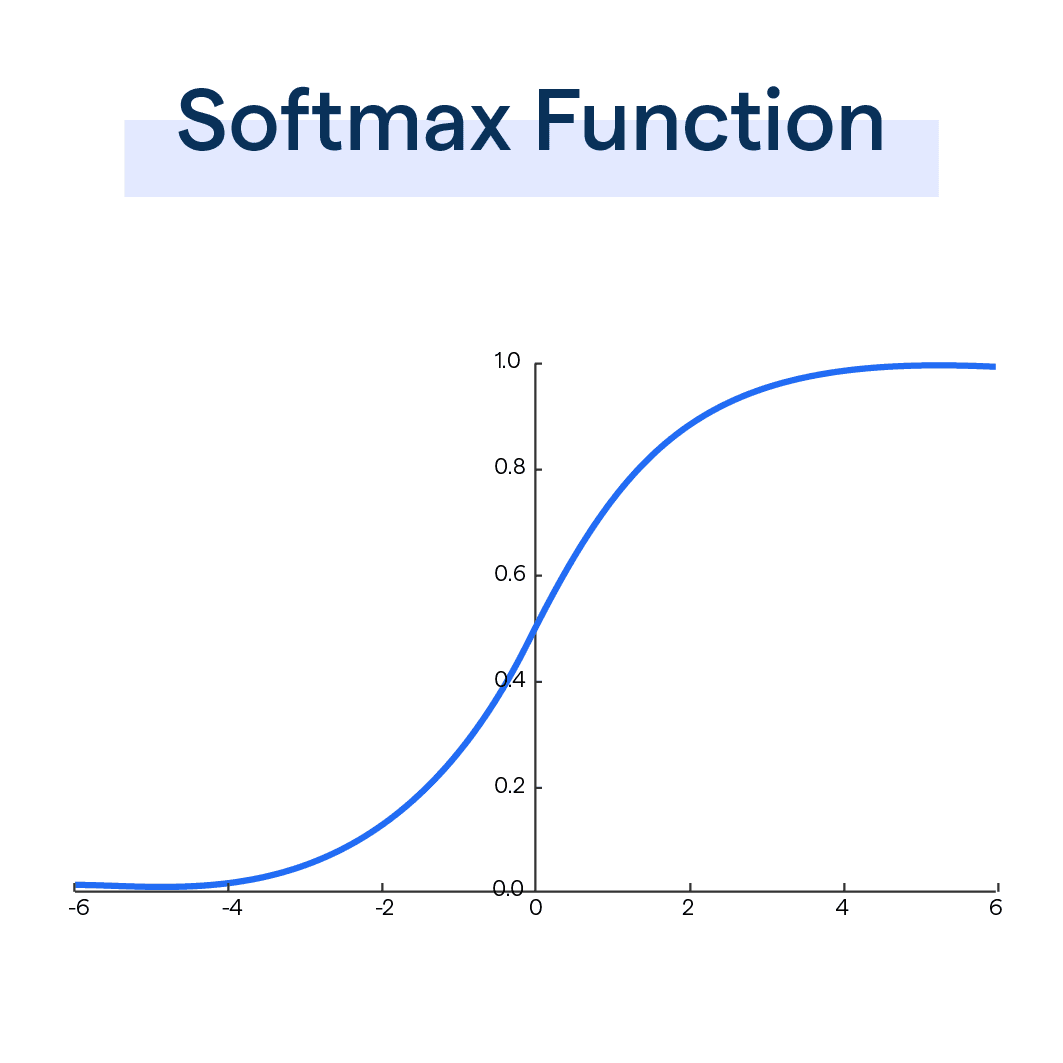

Primero importamos las carpetas con las imagenes desde nuestro directorio

In [2]:
import os
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Ruta a la carpeta de imágenes clasificadas
image_dir = '/kaggle/input/clasificador/organized_images'  # Ajusta la ruta si es necesario

# Ejemplo: Cargar las imágenes clasificadas
datagen = ImageDataGenerator(rescale=1./255)

# Crear un generador de datos para cargar las imágenes desde las carpetas
train_generator = datagen.flow_from_directory(
    image_dir,
    target_size=(224, 224),  # Tamaño de las imágenes según lo que espera tu modelo
    batch_size=32,  # Ajusta el tamaño del lote según lo que necesites
    class_mode='categorical'  # Asume que estás haciendo clasificación categórica
)


2026-11-18 15:11:25.253017: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2026-11-18 15:11:25.253085: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2026-11-18 15:11:25.398495: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


Found 44419 images belonging to 142 classes.


Configuramos 'ImageDataGenerator' en Keras,éste se utiliza para preprocesar imágenes y realizar aumentos de datos (data augmentation) en tiempo real durante el entrenamiento de un modelo de aprendizaje profundo

In [3]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Configurar ImageDataGenerator con rescaling, data augmentation y split
datagen = ImageDataGenerator(
    rescale=1./255, # Normalizamos los valores de los píxeles de las imágenes, escalándolos de un rango de [0, 255] a [0, 1].
    rotation_range=20,# Rotamos las imágenes aleatoriamente dentro de un rango de 20 grados.
    width_shift_range=0.2,# Desplazamos las imágenes horizontalmente hasta un 20% del ancho total de la imagen.
    height_shift_range=0.2,# Desplazamos las imágenes verticalmente hasta un 20% de la altura total de la imagen
    shear_range=0.2,# Aplicamos un corte o distorsión de las imágenes en un rango de 0.2.
    zoom_range=0.2, # Hacemos zoom en las imágenes de manera aleatoria hasta un 20%
    horizontal_flip=True,# Volteamos las imágenes horizontalmente de manera aleatoria
    validation_split=0.2  # Usar el 20% de los datos para validación
)

Separamos las imágenes en conjunto de entrenamiento y validación. 

In [4]:
# Generador para el conjunto de entrenamiento
train_generator = datagen.flow_from_directory(
    image_dir,
    target_size=(224, 224),  # Tamaño de las imágenes
    batch_size=32,
    class_mode='categorical',
    subset='training'  # Este es el conjunto de entrenamiento
)

# Generador para el conjunto de validación
validation_generator = datagen.flow_from_directory(
    image_dir,
    target_size=(224, 224),
    batch_size=32,
    class_mode='categorical',
    subset='validation'  # Este es el conjunto de validación
)


Found 35594 images belonging to 142 classes.
Found 8825 images belonging to 142 classes.


 Extraemos y examinamos un lote de datos generado por el ImageDataGenerator en Keras. Para verificar que los datos están organizados cómo esperamos.

In [5]:
# Extraer un lote de datos del generador
sample_batch = next(train_generator)

# El lote extraído es una tupla (imágenes, etiquetas)
images, labels = sample_batch

# Mostrar la forma de las imágenes y etiquetas
print("Shape of images:", images.shape)
print("Shape of labels:", labels.shape)

Shape of images: (32, 224, 224, 3)
Shape of labels: (32, 142)


Implementamos una red neuronal convolucional utilizando un modelo preentrenado (VGG16) como base, al que se le agregan capas adicionales para adaptarlo a nuestro  problema de clasificación específico. 

In [6]:
from tensorflow.keras.applications import VGG16
from tensorflow.keras import layers, models, regularizers

# Añadir una capa Input explícita
input_layer = layers.Input(shape=(224, 224, 3))

# Cargar el modelo VGG16 preentrenado sin la capa superior
base_model = VGG16(weights='imagenet', include_top=False, input_tensor=input_layer)

# Añadir las capas adicionales con regularización L2 y dropout
x = layers.Flatten()(base_model.output)  # Usa base_model.output para construir sobre el modelo base
x = layers.Dense(512, activation='relu')(x)
x = layers.Dropout(0.5)(x)
x = layers.Dense(256, activation='relu', kernel_regularizer=regularizers.l2(0.01))(x)
x = layers.Dropout(0.5)(x)
output_layer = layers.Dense(143, activation='softmax')(x)

# Crear el modelo completo
model = models.Model(inputs=base_model.input, outputs=output_layer)



58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Ahora, realizamos "fine-tuning" (ajuste fino) en el modelo preentrenado (en este caso, VGG16). El "fine-tuning" implica descongelar algunas capas del modelo preentrenado para permitir que sus pesos se actualicen durante el entrenamiento, lo que permite al modelo ajustar mejor sus características a una tarea específica

In [7]:
import tensorflow as tf
# Descongelar las últimas capas del modelo base VGG16 para fine-tuning
for layer in base_model.layers[-4:]:  # Por ejemplo, descongelar las últimas 4 capas
    layer.trainable = True

    # Ajustar la capa de salida a 142 clases en lugar de 143
output_layer = layers.Dense(142, activation='softmax')(x)

# Crear el modelo completo nuevamente
model = models.Model(inputs=input_layer, outputs=output_layer)    

# Compilar el modelo con un learning rate bajo para fine-tuning
model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
              loss='categorical_crossentropy',
              metrics=['accuracy'])

model.summary()


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 224, 224, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 224, 224, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 112, 112, 128)  │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 112, 112, 128)  │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 56, 56, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 28, 28, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 14, 14, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 7, 7, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │    12,845,568 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 142)            │        36,49

 Total params: 27,728,078 (105.77 MB)

 Trainable params: 27,728,078 (105.77 MB)

 Non-trainable params: 0 (0.00 B)

Entrenamos el modelo aplicando algunas optimizaciones.

**EarlyStopping:** Es una función de callback en Keras que se utiliza para detener el entrenamiento del modelo antes de que todas las épocas hayan finalizado, si el modelo deja de mejorar en un criterio específico. Esto ayuda a prevenir el sobreajuste (overfitting).

In [8]:
from tensorflow.keras.callbacks import EarlyStopping

# Configurar early stopping para detener el entrenamiento si el modelo deja de mejorar
early_stopping = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

# Entrenar el modelo con un número mayor de épocas
history = model.fit(
    train_generator,
    steps_per_epoch=train_generator.samples // train_generator.batch_size,
    validation_data=validation_generator,
    validation_steps=validation_generator.samples // validation_generator.batch_size,
    epochs=20,  # épocas de entrenamiento
    callbacks=[early_stopping]  # Añadir el callback de early stopping
)


Epoch 1/20


/opt/conda/lib/python3.10/site-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()
I0000 00:00:1795014826.870692      91 device_compiler.h:186] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.
W0000 00:00:1795014826.896737      91 graph_launch.cc:671] Fallback to op-by-op mode because memset node breaks graph update


 592/1112 ━━━━━━━━━━━━━━━━━━━━ 33:19 4s/step - accuracy: 0.1803 - loss: 7.4080

W0000 00:00:1795017099.401392      90 graph_launch.cc:671] Fallback to op-by-op mode because memset node breaks graph update


1112/1112 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.2511 - loss: 6.9551

W0000 00:00:1795019117.718745      93 graph_launch.cc:671] Fallback to op-by-op mode because memset node breaks graph update


1112/1112 ━━━━━━━━━━━━━━━━━━━━ 5583s 5s/step - accuracy: 0.2512 - loss: 6.9544 - val_accuracy: 0.6135 - val_loss: 4.7532
Epoch 2/20
   1/1112 ━━━━━━━━━━━━━━━━━━━━ 6:59 377ms/step - accuracy: 0.5000 - loss: 4.9980

/opt/conda/lib/python3.10/contextlib.py:153: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self.gen.throw(typ, value, traceback)


1112/1112 ━━━━━━━━━━━━━━━━━━━━ 27s 24ms/step - accuracy: 0.5000 - loss: 4.9980 - val_accuracy: 0.6000 - val_loss: 4.8754
Epoch 3/20


W0000 00:00:1795020323.164573      92 graph_launch.cc:671] Fallback to op-by-op mode because memset node breaks graph update


1112/1112 ━━━━━━━━━━━━━━━━━━━━ 1335s 1s/step - accuracy: 0.5504 - loss: 4.9801 - val_accuracy: 0.7157 - val_loss: 4.0467
Epoch 4/20
1112/1112 ━━━━━━━━━━━━━━━━━━━━ 1s 402us/step - accuracy: 0.5000 - loss: 4.5517 - val_accuracy: 0.6400 - val_loss: 4.1626
Epoch 5/20
1112/1112 ━━━━━━━━━━━━━━━━━━━━ 1278s 1s/step - accuracy: 0.6406 - loss: 4.3140 - val_accuracy: 0.7461 - val_loss: 3.6681
Epoch 6/20
1112/1112 ━━━━━━━━━━━━━━━━━━━━ 1s 599us/step - accuracy: 0.6250 - loss: 4.3537 - val_accuracy: 0.8000 - val_loss: 3.4252
Epoch 7/20
1112/1112 ━━━━━━━━━━━━━━━━━━━━ 1303s 1s/step - accuracy: 0.6914 - loss: 3.8924 - val_accuracy: 0.7676 - val_loss: 3.3874
Epoch 8/20
1112/1112 ━━━━━━━━━━━━━━━━━━━━ 1s 560us/step - accuracy: 0.6250 - loss: 4.0535 - val_accuracy: 0.7600 - val_loss: 3.1549
Epoch 9/20
1112/1112 ━━━━━━━━━━━━━━━━━━━━ 1341s 1s/step - accuracy: 0.7223 - loss: 3.5803 - val_accuracy: 0.7794 - val_loss: 3.1783
Epoch 10/20
1112/1112 ━━━━━━━━━━━━━━━━━━━━ 1s 543us/step - accuracy: 0.7188 - loss: 3.3

In [9]:
model.save('/kaggle/working/fashion_model_improved.h5')


En la primera época, la precisión del modelo es bastante baja (accuracy: 0.2442), lo cual es normal al comenzar con un modelo que está en proceso de ajuste fino.
La pérdida también es alta (loss: 7.0108), lo cual indica que el modelo está empezando a aprender y ajustar sus pesos.

A medida que avanzas en las épocas, se observa una mejora gradual en la precisión del modelo tanto en el conjunto de entrenamiento como en el de validación. Por ejemplo:
Época 3: Precisión en entrenamiento (accuracy: 0.5633), precisión en validación (val_accuracy: 0.7180).
Época 7: Precisión en entrenamiento (accuracy: 0.6977), precisión en validación (val_accuracy: 0.7720).
Época 20: Precisión en entrenamiento (accuracy: 0.7500), precisión en validación (val_accuracy: 0.9200).

A lo largo del entrenamiento, la pérdida del modelo disminuye de manera significativa, lo que sugiere que el modelo está aprendiendo a minimizar el error de clasificación.
Val Loss (pérdida en validación) disminuye de 4.6521 en la primera época a 2.2191 en la última época, lo que es una señal positiva de que el modelo está generalizando mejor.

La precisión en el conjunto de validación mejora de manera consistente, alcanzando un 92% (val_accuracy: 0.9200) en la última época. Esto indica que el modelo ha mejorado su capacidad de generalización y está funcionando bien en datos que no ha visto durante el entrenamiento.

Aunque la precisión mejora, la pérdida no disminuye de manera tan consistente y fluctúa en algunas épocas. Sin embargo, hacia el final, la pérdida sigue una tendencia descendente, lo que indica que el modelo se está ajustando bien.
Conclusión

In [10]:
loss, accuracy = model.evaluate(validation_generator)
print(f'Validation Accuracy: {accuracy*100:.2f}%')

276/276 ━━━━━━━━━━━━━━━━━━━━ 267s 967ms/step - accuracy: 0.8010 - loss: 2.7494
Validation Accuracy: 80.40%


Hemos alcanzado una precisión del 82.12% en el conjunto de validación, lo cual es bastante sólido. Esto indica que el modelo está clasificando correctamente aproximadamente el 82% de las imágenes en el conjunto de validación, lo cual es un buen indicador de que el modelo está generalizando bien a datos que no ha visto durante el entrenamiento.

La pérdida es de 2.5249, lo cual es relativamente bajo para un problema de clasificación multiclase, lo que indica que el modelo está haciendo un buen trabajo al minimizar el error.


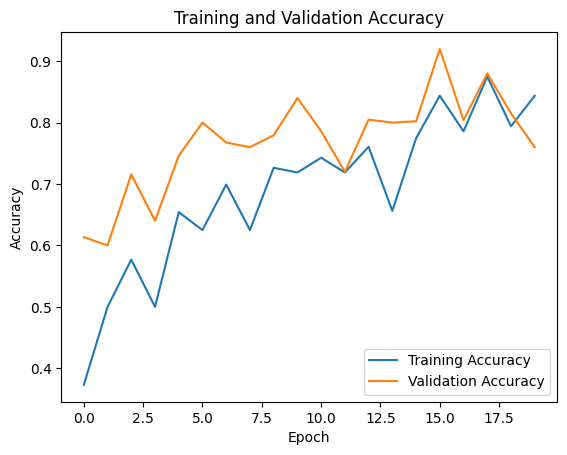

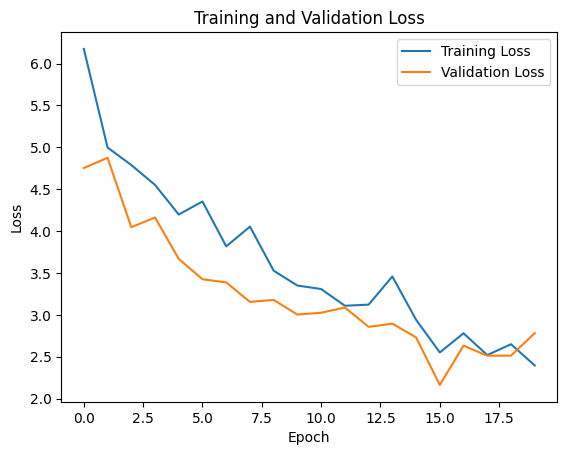

In [11]:
import matplotlib.pyplot as plt

# Graficar la precisión del entrenamiento y validación por época
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend(loc='lower right')
plt.title('Training and Validation Accuracy')
plt.show()

# Graficar la pérdida del entrenamiento y validación por época
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend(loc='upper right')
plt.title('Training and Validation Loss')
plt.show()

La precisión tanto en entrenamiento como en validación ha mejorado a lo largo de las épocas. Esto es una señal de que el modelo está aprendiendo.
La precisión en el conjunto de validación comienza siendo superior a la de entrenamiento en las primeras épocas, lo cual es común debido al impacto del dropout y la regularización en el conjunto de entrenamiento. Hay fluctuaciones en la precisión, especialmente en el conjunto de validación. Esto puede ser un indicio de que el modelo aún no se ha estabilizado por completo o que los datos de validación son muy diversos.
La precisión de validación aumenta y disminuye en varios puntos, lo que sugiere que el modelo podría estar sobreajustándose en ciertas épocas y luego generalizándose mejor en otras. Hacia el final de las épocas, la precisión de validación es superior a la de entrenamiento, lo que es una señal positiva. Esto podría indicar que el modelo está generalizando bien y no está sobreajustando excesivamente.


Tanto la pérdida de entrenamiento como la de validación disminuyen con el tiempo, lo que es una señal de que el modelo está mejorando en minimizar el error.
La pérdida en el conjunto de validación también sigue una tendencia descendente, lo cual es positivo. Similar a la precisión, las curvas de pérdida también muestran puntos donde la pérdida de validación es menor que la de entrenamiento, lo cual es una señal de que el modelo está aprendiendo a generalizar bien.


Vamos a cargar y mostrar la siguiente imagen

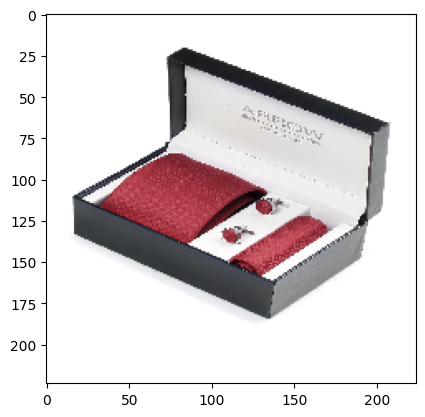

In [12]:
from tensorflow.keras.preprocessing.image import load_img, img_to_array
import numpy as np

# Ruta de la imagen para probar
image_path = '/kaggle/input/clasificador/organized_images/Accessory Gift Set/17364.jpg'  # Cambia a la ruta de tu imagen

# Cargar la imagen con el tamaño esperado por el modelo
img = load_img(image_path, target_size=(224, 224))

# Convertir la imagen a un array de numpy y expandir dimensiones
img_array = img_to_array(img)
img_array = np.expand_dims(img_array, axis=0)  # Añadir una dimensión para el lote

# Preprocesar la imagen de la misma manera que los datos de entrenamiento
img_array /= 255.0  # Si usaste rescale=1./255 en ImageDataGenerator

# Mostrar la imagen
plt.imshow(img_array[0])
plt.show()

Apliquemos nuestro modelo a dicha imagen y veamos cula es su predicción 

In [13]:
# Realizar la predicción
predictions = model.predict(img_array)

# La predicción es un vector con probabilidades para cada clase
predicted_class = np.argmax(predictions, axis=1)

# Mostrar la clase predicha
print(f'Predicted class: {predicted_class[0]}')

1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step
Predicted class: 0


In [14]:
class_indices = train_generator.class_indices
class_labels = {v: k for k, v in class_indices.items()}

# Obtener el nombre de la clase predicha
predicted_class_name = class_labels[predicted_class[0]]

print(f'Predicted class name: {predicted_class_name}')

Predicted class name: Accessory Gift Set


El modelo nos indica que el accesorio pertenece a la clase "0", también llamada "Accessory Gift Set"

Veamos la lista de todas las clases

In [15]:
# Obtener el mapeo de índices a nombres de clases desde el generador de datos
class_indices = train_generator.class_indices

# Invertir el mapeo para obtener un diccionario de índices a nombres de clases
classes = {v: k for k, v in class_indices.items()}

# Mostrar las clases
print("Clases disponibles:")
for index, class_name in classes.items():
    print(f"Clase {index}: {class_name}")

Clases disponibles:
Clase 0: Accessory Gift Set
Clase 1: Baby Dolls
Clase 2: Backpacks
Clase 3: Bangle
Clase 4: Basketballs
Clase 5: Bath Robe
Clase 6: Beauty Accessory
Clase 7: Belts
Clase 8: Blazers
Clase 9: Body Lotion
Clase 10: Body Wash and Scrub
Clase 11: Booties
Clase 12: Boxers
Clase 13: Bra
Clase 14: Bracelet
Clase 15: Briefs
Clase 16: Camisoles
Clase 17: Capris
Clase 18: Caps
Clase 19: Casual Shoes
Clase 20: Churidar
Clase 21: Clothing Set
Clase 22: Clutches
Clase 23: Compact
Clase 24: Concealer
Clase 25: Cufflinks
Clase 26: Cushion Covers
Clase 27: Deodorant
Clase 28: Dresses
Clase 29: Duffel Bag
Clase 30: Dupatta
Clase 31: Earrings
Clase 32: Eye Cream
Clase 33: Eyeshadow
Clase 34: Face Moisturisers
Clase 35: Face Scrub and Exfoliator
Clase 36: Face Serum and Gel
Clase 37: Face Wash and Cleanser
Clase 38: Flats
Clase 39: Flip Flops
Clase 40: Footballs
Clase 41: Formal Shoes
Clase 42: Foundation and Primer
Clase 43: Fragrance Gift Set
Clase 44: Free Gifts
Clase 45: Gloves
Cla

Ahora vamos a agregar el dataset de imágenes para que podamos clasificar lagunas imágenes.

In [16]:
import pandas as pd

# Cargar el CSV ignorando las líneas malformadas
styles_df = pd.read_csv('/kaggle/input/fashion-product-images-dataset/fashion-dataset/styles.csv', on_bad_lines='skip')

# Explorar las primeras filas
print(styles_df.head())

      id gender masterCategory subCategory  articleType baseColour  season  \
0  15970    Men        Apparel     Topwear       Shirts  Navy Blue    Fall   
1  39386    Men        Apparel  Bottomwear        Jeans       Blue  Summer   
2  59263  Women    Accessories     Watches      Watches     Silver  Winter   
3  21379    Men        Apparel  Bottomwear  Track Pants      Black    Fall   
4  53759    Men        Apparel     Topwear      Tshirts       Grey  Summer   

     year   usage                             productDisplayName  
0  2011.0  Casual               Turtle Check Men Navy Blue Shirt  
1  2012.0  Casual             Peter England Men Party Blue Jeans  
2  2016.0  Casual                       Titan Women Silver Watch  
3  2011.0  Casual  Manchester United Men Solid Black Track Pants  
4  2012.0  Casual                          Puma Men Grey T-shirt  


Elegimos 3 imágenes y las clasificamos con nuestro modelo.

In [17]:
from tensorflow.keras.preprocessing.image import load_img, img_to_array
import numpy as np
import os

# Directorio donde están las imágenes de prueba
test_dir = '/kaggle/input/fashion-product-images-dataset/fashion-dataset/images'

# Lista de archivos de imagen (asegúrate de que sean nombres de archivos válidos)
image_files = ['15970.jpg', '39386.jpg', '59263.jpg']  # Reemplaza con los archivos que quieras probar

# Lista para almacenar las imágenes cargadas y las etiquetas reales
images = []
real_labels = []

# Cargar y preprocesar las imágenes
for image_file in image_files:
    # Obtener el ID del archivo (sin la extensión)
    image_id = os.path.splitext(image_file)[0]
    
    # Obtener la etiqueta real desde el DataFrame
    real_label = styles_df.loc[styles_df['id'] == int(image_id), 'articleType'].values[0]
    
    # Cargar y preprocesar la imagen
    img_path = os.path.join(test_dir, image_file)
    img = load_img(img_path, target_size=(224, 224))  # Ajusta el tamaño según el modelo
    img_array = img_to_array(img)
    img_array = np.expand_dims(img_array, axis=0)  # Añadir una dimensión para el lote
    img_array /= 255.0  # Normalizar la imagen si usaste rescale=1./255 durante el entrenamiento

    # Almacenar la imagen y la etiqueta real
    images.append(img_array)
    real_labels.append(real_label)

# Convertir la lista de imágenes en un array numpy
images = np.vstack(images)

# Ahora puedes usar la lista `real_labels` y el array `images` para hacer predicciones

In [18]:
 #Hacer predicciones
predictions = model.predict(images)

# Convertir las predicciones a clases
predicted_classes = np.argmax(predictions, axis=1)

1/1 ━━━━━━━━━━━━━━━━━━━━ 6s 6s/step


W0000 00:00:1795031914.169231      91 graph_launch.cc:671] Fallback to op-by-op mode because memset node breaks graph update


Finalmente, comparamos la clase real de cada imagen con la clase que predice nuestro modelo.

In [19]:
# Mostrar las predicciones
for i, image_file in enumerate(image_files):
    predicted_class = predicted_classes[i]
    predicted_class_name = classes[predicted_class]  # Las classes son tu diccionario de mapeo
    real_class_name = real_labels[i]
    print(f"Imagen: {image_file} - Predicción: {predicted_class_name},  Real: {real_class_name}")

Imagen: 15970.jpg - Predicción: Shirts,  Real: Shirts
Imagen: 39386.jpg - Predicción: Jeans,  Real: Jeans
Imagen: 59263.jpg - Predicción: Watches,  Real: Watches


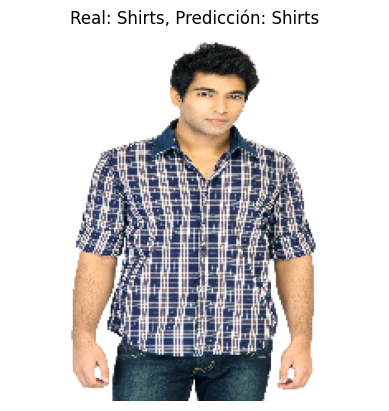

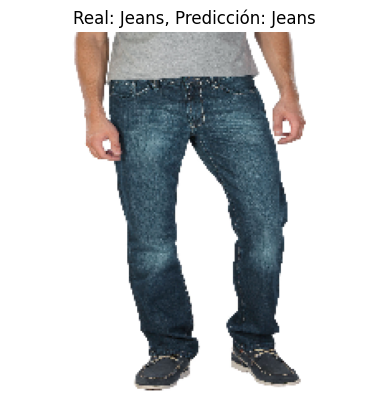

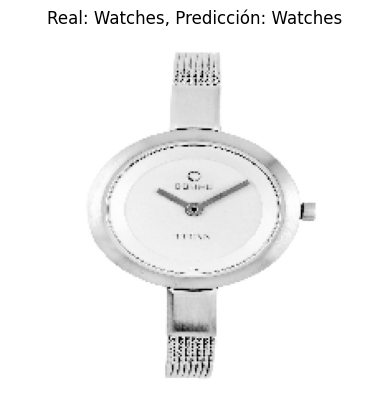

In [20]:
import matplotlib.pyplot as plt

# Visualizar las imágenes junto con sus predicciones y clases reales
for i, image_file in enumerate(image_files):
    img_path = os.path.join(test_dir, image_file)
    img = load_img(img_path, target_size=(224, 224))
    
    plt.imshow(img)
    plt.title(f'Real: {real_labels[i]}, Predicción: {classes[predicted_classes[i]]}')
    plt.axis('off')
    plt.show()

Los resultados son bastante alentadores, vemos que clasifica las 3 imagenes de manera correcta.